# 🐱🐶 Cats vs Dogs Classifier (Transfer Learning with MobileNetV2)
# 
# **Goal:** Classify images of cats and dogs with high accuracy using transfer learning.
# 
# **Dataset:** `cats_vs_dogs` from TensorFlow Datasets (~23,000 images).
# 
# **Approach:**  
# - Load pre-trained **MobileNetV2** without top layer (`include_top=False`)  
# - Add custom classification head  
# - Two-phase training (frozen base → fine-tuning)  
# - Data augmentation for robustness
# 
# **Expected Accuracy:** 98%+
# 
# ---
# 
# **Author:** Your Name  
# **Platform:** Kaggle GPU  
# **Framework:** TensorFlow / Keras

In [10]:
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np
import os

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.18.0


# ## 1. Load the Dataset
# We'll use `cats_vs_dogs` from TensorFlow Datasets.  
# This dataset has ~23,000 images split into training and validation sets.


In [11]:
(ds_train, ds_val), ds_info = tfds.load(
    'cats_vs_dogs',
    split=['train[:80%]', 'train[80%:]'],
    shuffle_files=True,
    as_supervised=True,  # (image, label) format
    with_info=True
)

print(ds_info)

tfds.core.DatasetInfo(
    name='cats_vs_dogs',
    full_name='cats_vs_dogs/4.0.1',
    description="""
    A large set of images of cats and dogs. There are 1738 corrupted images that are dropped.
    """,
    homepage='https://www.microsoft.com/en-us/download/details.aspx?id=54765',
    data_dir='/root/tensorflow_datasets/cats_vs_dogs/4.0.1',
    file_format=tfrecord,
    download_size=786.67 MiB,
    dataset_size=1.04 GiB,
    features=FeaturesDict({
        'image': Image(shape=(None, None, 3), dtype=uint8),
        'image/filename': Text(shape=(), dtype=string),
        'label': ClassLabel(shape=(), dtype=int64, num_classes=2),
    }),
    supervised_keys=('image', 'label'),
    disable_shuffling=False,
    nondeterministic_order=False,
    splits={
        'train': <SplitInfo num_examples=23262, num_shards=16>,
    },
    citation="""@Inproceedings (Conference){asirra-a-captcha-that-exploits-interest-aligned-manual-image-categorization,
    author = {Elson, Jeremy and Douceur, Jo

# ## 2. Visualize Some Images


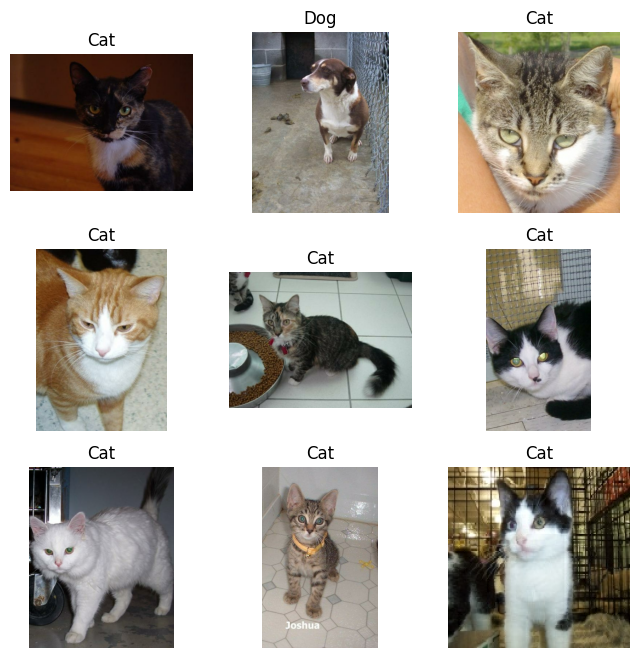

In [12]:
plt.figure(figsize=(8, 8))
for i, (image, label) in enumerate(ds_train.take(9)):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title("Cat" if label == 0 else "Dog")
    plt.axis("off")

# ## 3. Data Preprocessing & Augmentation

In [13]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def format_image(image, label):
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    return image, label

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

train_ds = ds_train.map(format_image).cache().shuffle(1000).batch(BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = ds_val.map(format_image).cache().batch(BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)


# ## 4. Build the Transfer Learning Model (MobileNetV2)

In [14]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False  # Freeze base model

inputs = layers.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation='sigmoid')(x)
model = models.Model(inputs, outputs)


model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 # 5. Phase 1 Training (Frozen Base Model)

In [15]:
initial_epochs = 5
history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=initial_epochs
)

Epoch 1/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 45s 64ms/step - accuracy: 0.9599 - loss: 0.1014 - val_accuracy: 0.9871 - val_loss: 0.0389
Epoch 2/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 31s 53ms/step - accuracy: 0.9797 - loss: 0.0572 - val_accuracy: 0.9873 - val_loss: 0.0325
Epoch 3/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 31s 53ms/step - accuracy: 0.9792 - loss: 0.0543 - val_accuracy: 0.9893 - val_loss: 0.0303
Epoch 4/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 31s 53ms/step - accuracy: 0.9813 - loss: 0.0500 - val_accuracy: 0.9895 - val_loss: 0.0310
Epoch 5/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 31s 52ms/step - accuracy: 0.9807 - loss: 0.0469 - val_accuracy: 0.9901 - val_loss: 0.0313


# ## 6. Phase 2 Training (Fine-Tuning)
# We unfreeze the later halflayers of MobileNetV2 and train with a low learning rate.


In [16]:
base_model.trainable = True
fine_tune_at = len(base_model.layers) // 2  # fine-tune half the layers

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=5e-6),
              loss='binary_crossentropy',
              metrics=['accuracy'])


fine_tune_epochs = 5
total_epochs = initial_epochs + fine_tune_epochs

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=total_epochs,
    initial_epoch=history1.epoch[-1]
)

Epoch 5/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 75s 92ms/step - accuracy: 0.9121 - loss: 0.2228 - val_accuracy: 0.9824 - val_loss: 0.0575
Epoch 6/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 51s 88ms/step - accuracy: 0.9666 - loss: 0.0854 - val_accuracy: 0.9854 - val_loss: 0.0455
Epoch 7/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 52s 89ms/step - accuracy: 0.9668 - loss: 0.0814 - val_accuracy: 0.9873 - val_loss: 0.0388
Epoch 8/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 51s 88ms/step - accuracy: 0.9717 - loss: 0.0719 - val_accuracy: 0.9875 - val_loss: 0.0376
Epoch 9/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 51s 88ms/step - accuracy: 0.9782 - loss: 0.0616 - val_accuracy: 0.9880 - val_loss: 0.0358
Epoch 10/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 51s 88ms/step - accuracy: 0.9790 - loss: 0.0535 - val_accuracy: 0.9890 - val_loss: 0.0340


# ## 7. Plot Training Curves

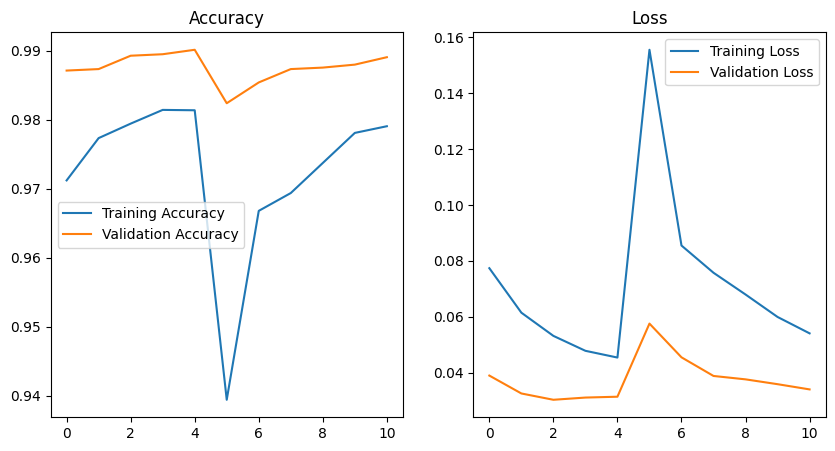

In [17]:
acc = history1.history['accuracy'] + history2.history['accuracy']
val_acc = history1.history['val_accuracy'] + history2.history['val_accuracy']
loss = history1.history['loss'] + history2.history['loss']
val_loss = history1.history['val_loss'] + history2.history['val_loss']

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend()
plt.title('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend()
plt.title('Loss')
plt.show()


## 8. Evaluate Final Model

In [18]:
loss, accuracy = model.evaluate(val_ds)
print(f"Validation Accuracy: {accuracy * 100:.2f}%")

146/146 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - accuracy: 0.9872 - loss: 0.0380
Validation Accuracy: 98.90%
